# 12 — n-step Q(σ) Prediction

고정 Target Policy의 Qπ를 추정하는 **Policy Evaluation** 예제다. L.OffPolicyNStepSARSA가 학습 계산을 담당한다. 환경·Window·행동 선택 순서는 아래 루프에 명시한다.

### 실행 설정
`MODULARRL_FAST=1`은 CI용 FAST, 기본값은 FULL입니다. 각 Notebook은 독립 Kernel에서 실행합니다. 처음부터 Run All하면 RNG·Model·학습 상태를 다시 만듭니다.

In [1]:
from pathlib import Path
import os, sys, json
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import gymnasium as gym
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from copy import deepcopy
from collections import deque
from modular_rl import Model
from modular_rl import representations as R, estimators as E, selectors as S
from modular_rl import buffers as B, targets as T, updates as U, learners as L
from modular_rl.data import Transition, Episode
from modular_rl.dp import policy_evaluation, policy_iteration, value_iteration, uniform_policy, action_values
from notebooks.gymnasium.tutorial_utils import (frozenlake_mdp, evaluate, history, record, frozen_report, neural_report)
FAST = os.environ.get('MODULARRL_FAST', '0') == '1'  # 기본 FULL, CI는 FAST=1
SEED = 7
GAMMA = .99
np_rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.close('all')
print({'mode': 'FAST' if FAST else 'FULL', 'seed': SEED, 'gamma': GAMMA, 'device': 'cpu'})

{'mode': 'FAST', 'seed': 7, 'gamma': 0.99, 'device': 'cpu'}


In [2]:
env = gym.make('FrozenLake-v1', map_name='4x4', is_slippery=False, max_episode_steps=1000)
eval_env = gym.make('FrozenLake-v1', map_name='4x4', is_slippery=False, max_episode_steps=100)
N_STATES, N_ACTIONS = int(env.observation_space.n), int(env.action_space.n)
print(env.observation_space, env.action_space)
desc = env.unwrapped.desc.copy()

Discrete(16) Discrete(4)


In [3]:
representation = R.Identity()  # 정수 State Index를 유지한다.
estimator = E.TabularQ(N_STATES, N_ACTIONS)
selector = S.EpsilonGreedy(1.)
model = Model(representation, estimator, selector).double()
target_generator = T.TD0(GAMMA)
update_rule = U.TabularQ(.5)
selector.epsilon = 1.
update_rule = U.TabularQ(.05)
target_policy = torch.tensor([[.3,.2,.2,.3]]*N_STATES, dtype=torch.float64)
learner = L.QSigma(model, target_generator, update_rule, target_policy=target_policy)
mdp = frozenlake_mdp(env)
N = 3
log = history()

### Q(σ)의 경계 정의
이 예제는 교재 본문 식 (7.17)의 G(h:h)=Q(S_h,A_h)를 선택한다. 마지막 차분이 0이므로
비종료/Truncation에서는 R_h+γVπ(S_h), 자연 종료에서는 R_T로 시작한다. Horizon 행동을 추가 샘플링하지 않는다.
중간 행동에만 σρ+(1−σ)π를 쓰고 별도의 전체 IS Ratio를 다시 곱하지 않는다.
σ=0은 Tree Backup이며 σ=1은 Control Variate를 포함하므로 Sampled SARSA와 표본별로 같을 필요가 없다.
교재 §7.6 의사코드와 본문의 경계 해석 차이를 기록한 것이며 공식 정오표에서 인정된 오류로 단정하지 않는다.

In [4]:
for episode_index in range(60 if FAST else 3000):
    observation, _ = env.reset(seed=SEED if episode_index == 0 else None)
    selected = model.act(observation)
    pending = deque()
    pending_sigmas = deque()
    total, length = 0., 0
    while True:
        next_observation, reward, terminated, truncated, _ = env.step(selected.action.item())
        reward = float(reward)  # 학습 reward의 floating 계약

        pending.append(Transition(observation, selected.action, reward, next_observation, terminated, truncated, selected.log_prob).to_batch())
        pending_sigmas.append((0., .5, 1.)[length % 3])  # 실제 행동 시점의 sigma
        if len(pending) == N:
            result = learner.learn(pending,
                    sigma=[*list(pending_sigmas)[1:], 0.])
            pending.popleft()
            pending_sigmas.popleft()
        total += reward; length += 1
        if terminated or truncated:
            while pending:
                result = learner.learn(pending,
                    sigma=[*list(pending_sigmas)[1:], 0.])
                pending.popleft()
                pending_sigmas.popleft()
            break
        observation = next_observation
        selected = model.act(observation)
    record(log, total, length, terminated, truncated)
reference = policy_evaluation(mdp, target_policy.numpy(), gamma=GAMMA).values
q_reference = action_values(mdp, reference, GAMMA)
nonterminal = [s for s in range(N_STATES) if s not in mdp.terminal_states]
print('fixed-target Qpi RMSE', float(np.sqrt(np.mean((model.estimator.q_table.numpy()[nonterminal]-q_reference[nonterminal])**2))))

fixed-target Qpi RMSE 0.15140424550144943


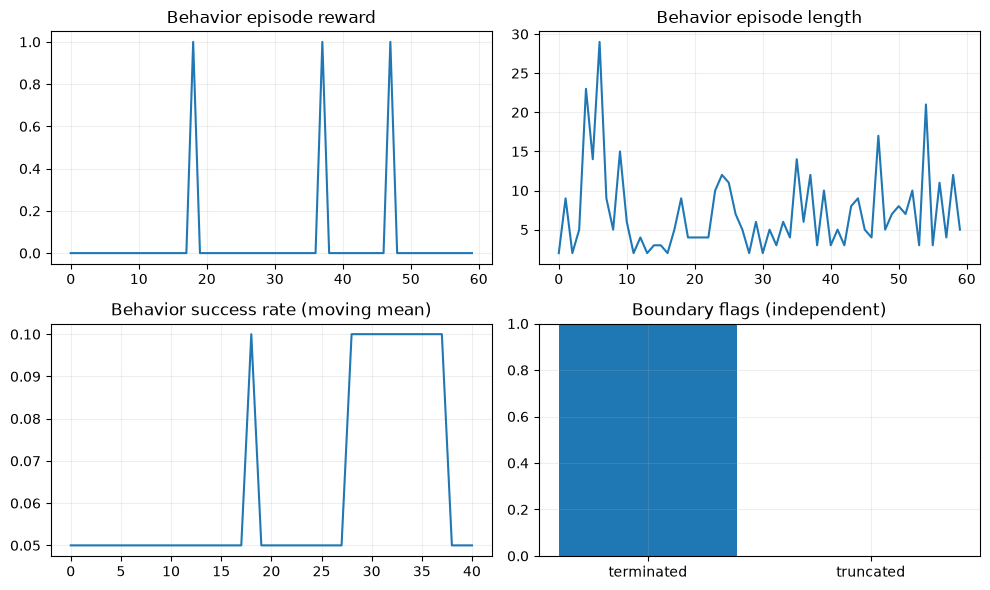

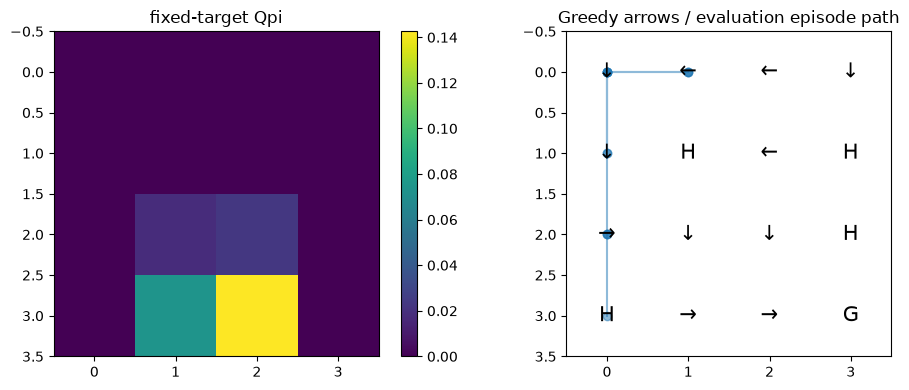

fixed-target Qpi [[ 0.000e+00  1.000e-04 -0.000e+00 -0.000e+00]
 [ 0.000e+00  0.000e+00 -0.000e+00 -0.000e+00]
 [ 0.000e+00  0.000e+00 -0.000e+00  0.000e+00]
 [-0.000e+00  0.000e+00  0.000e+00  0.000e+00]
 [ 1.000e-04  2.000e-04  0.000e+00  0.000e+00]
 [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00]
 [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00]
 [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00]
 [-1.000e-04  0.000e+00  5.000e-04  0.000e+00]
 [ 0.000e+00  1.800e-02  4.800e-03  0.000e+00]
 [ 1.000e-04  2.330e-02  0.000e+00  0.000e+00]
 [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00]
 [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00]
 [ 0.000e+00  1.830e-02  7.370e-02  0.000e+00]
 [ 0.000e+00  0.000e+00  1.426e-01  5.000e-04]
 [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00]]
RESULT {"environment_steps": 433, "episodes": 60, "evaluation_mean_reward": 0.0, "evaluation_success": 0.0, "terminated_rate": 1.0, "truncated_rate": 0.0}


In [5]:
model.eval()
evaluation = evaluate(eval_env, lambda state: np_rng.choice(N_ACTIONS, p=target_policy[state].numpy()), episodes=5 if FAST else 100, seed=SEED+1000)
table = model.estimator.q_table.detach().cpu().numpy()
greedy_actions = table.argmax(-1)
summary = frozen_report(desc, log, table, evaluation, greedy_actions=greedy_actions, label='fixed-target Qpi')
env.close(); eval_env.close()

### 이번 조합에서 드러난 API 특성
고정 정책과 Behavior 확률, 시간순 Window를 호출자가 전달한다. 마지막 Bootstrap 평가와 행동 선택 순서는 알고리즘마다 다르다. 학습 계산은 공식 Learner가 담당하고 시간순 Window는 무작위 SequenceReplay로 대체하지 않는다.

### API 사용성 기록 — 아래 빈칸을 직접 수정해 보세요

|질문|실행 후 관찰/개선 제안|
|---|---|
|Model 생성이 자연스러운가?| |
|Learner 구성은 직관적인가?| |
|TargetGenerator를 선택하기 쉬운가?| |
|Buffer의 사용법이 일관적인가?| |
|Experience 자료형을 직접 조작할 필요가 있는가?| |
|학습 호출이 간결한가?| |
|Algorithm-specific 코드가 얼마나 필요한가?| |
|불필요한 자료형 변환이 존재하는가?| |
|API만 보고 학습 과정이 이해되는가?| |
|공용 컴포넌트로 옮길 필요가 있는 코드가 있는가?| |

FAST는 연결과 Shape 검사용이며 성능 판정이 아니다. FULL은 실제 학습용이다.
Seed 하나의 성공률로 알고리즘의 정확성을 판단하지 않는다. `terminated`와 `truncated`는
독립적인 flag이며 실제 마지막 관측을 저장한다. 아래 helper는 시각화·평가만 담당하고 학습을 숨기지 않는다.